In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [ ]:
# Black-Scholes Delta and Vega functions
def bs_delta(S, K, T, r, sigma):
    T = np.maximum(T, 1e-6)  # Avoid division by zero at expiry
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return norm.cdf(d1)

def bs_vega(S, K, T, r, sigma):
    T = np.maximum(T, 1e-6)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)

def bs_vanna(S, K, T, r, sigma):
    T = np.maximum(T, 1e-6)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return -norm.pdf(d1) * (d2 / sigma)

In [ ]:
# Simulation Parameters
np.random.seed(571)
days = 120
dt = 1 / 252
T_init = days * dt
S0 = 100.0
K = 105.0          # Slightly OTM Call (where Vanna is pronounced)
r = 0.03
sigma0 = 0.20      # Initial 20% volatility assumption

# Simulate Correlated Spot and Implied Volatility Paths
# In reality, vol spikes when spot drops (negative correlation rho) plus regime noise
rho = -0.75
vol_of_vol = 0.85

Z1 = np.random.normal(0, 1, days)
Z2 = rho * Z1 + np.sqrt(1 - rho**2) * np.random.normal(0, 1, days)

S = np.zeros(days)
sigma_imp = np.zeros(days)
time_to_expiry = np.linspace(T_init, dt, days)

S[0] = S0
sigma_imp[0] = sigma0

for t in range(1, days):
    # Spot follows geometric evolution with time-varying vol
    dW_S = Z1[t] * np.sqrt(dt)
    S[t] = S[t-1] * np.exp((r - 0.5 * sigma_imp[t-1]**2) * dt + sigma_imp[t-1] * dW_S)
    
    # Implied volatility has sticky-delta skew + stochastic vol-of-vol jumps
    skew_effect = -0.4 * ((S[t] - S0) / S0)
    stochastic_vol_shock = sigma_imp[t-1] * vol_of_vol * Z2[t] * np.sqrt(dt)
    mean_reversion = 2.0 * (sigma0 + skew_effect - sigma_imp[t-1]) * dt
    
    sigma_imp[t] = np.clip(sigma_imp[t-1] + mean_reversion + stochastic_vol_shock, 0.08, 0.80)

#  Compute Hedge Ratios Under Both Regimes
#  Constant Volatility Assumption 
delta_const_vol = bs_delta(S, K, time_to_expiry, r, sigma0)

# Changing Volatility Assumption 
delta_changing_vol = bs_delta(S, K, time_to_expiry, r, sigma_imp)

# Decompose the daily Delta change into Gamma effect vs Vanna effect 
d_delta_const = np.diff(delta_const_vol)
d_delta_changing = np.diff(delta_changing_vol)
vanna_pollution = d_delta_changing - d_delta_const



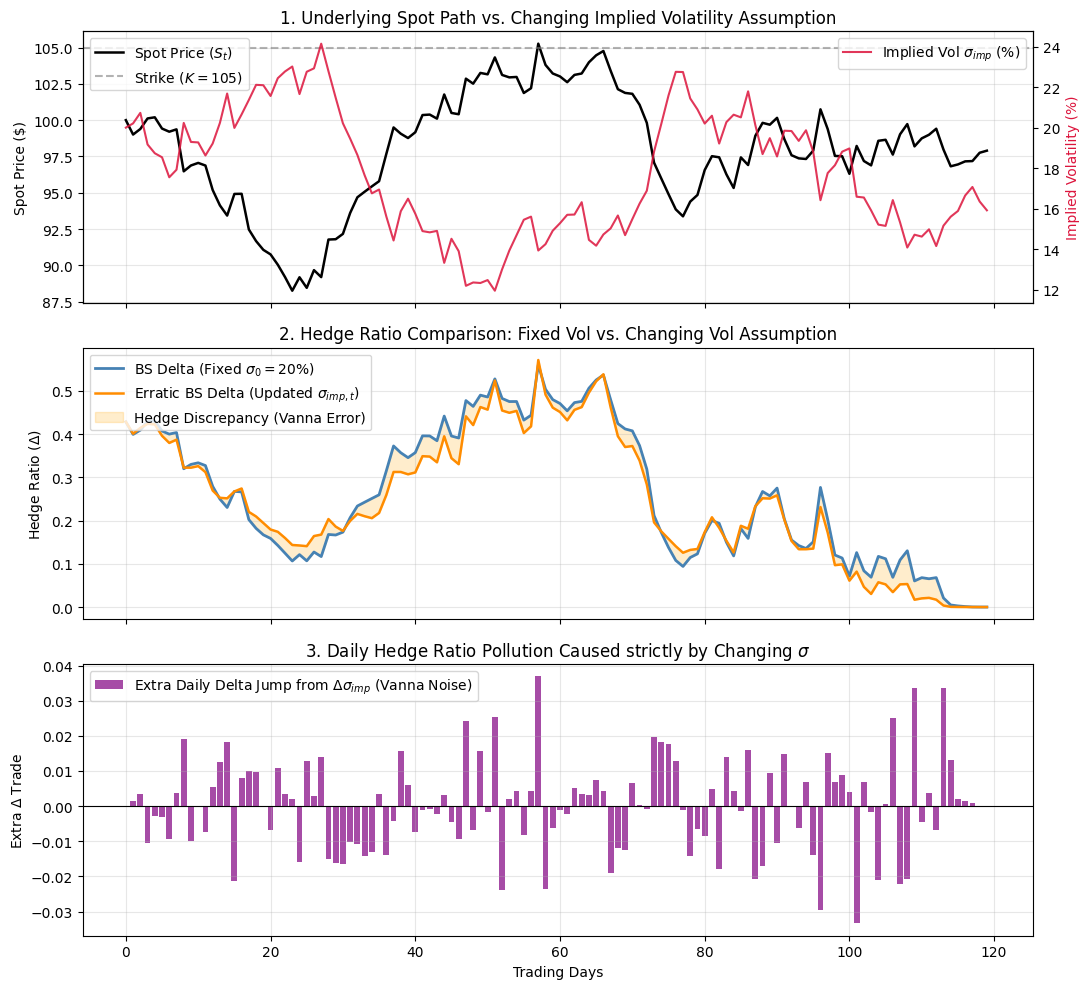

Total Shares Traded (Fixed Vol):    3.35
Total Shares Traded (Changing Vol): 2.95
Excess Trading Volume from Vol Adjustments: +-12.0%


In [ ]:
# Plot the Results
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

# Spot Price & Changing Volatility Assumption
ax1 = axes[0]
ax1_vol = ax1.twinx()
ax1.plot(S, color='black', lw=1.8, label='Spot Price ($S_t$)')
ax1.axhline(K, color='gray', linestyle='--', alpha=0.6, label='Strike ($K=105$)')
ax1_vol.plot(sigma_imp * 100, color='crimson', lw=1.5, alpha=0.85, label='Implied Vol $\sigma_{imp}$ (%)')
ax1.set_ylabel('Spot Price ($)')
ax1_vol.set_ylabel('Implied Volatility (%)', color='crimson')
ax1.set_title('1. Underlying Spot Path vs. Changing Implied Volatility Assumption')
ax1.legend(loc='upper left')
ax1_vol.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Constant-Vol Delta vs. Re-Marked BS Delta
ax2 = axes[1]
ax2.plot(delta_const_vol, label='BS Delta (Fixed $\sigma_0 = 20\%$)', color='steelblue', lw=2)
ax2.plot(delta_changing_vol, label='Erratic BS Delta (Updated $\sigma_{imp, t}$)', color='darkorange', lw=1.8, linestyle='-')
ax2.fill_between(range(days), delta_const_vol, delta_changing_vol, color='orange', alpha=0.2, label='Hedge Discrepancy (Vanna Error)')
ax2.set_ylabel('Hedge Ratio ($\Delta$)')
ax2.set_title('2. Hedge Ratio Comparison: Fixed Vol vs. Changing Vol Assumption')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# Daily Re-Hedging Turnover / Erratic Adjustments
ax3 = axes[2]
ax3.bar(range(1, days), vanna_pollution, color='purple', alpha=0.7, label='Extra Daily Delta Jump from $\Delta \sigma_{imp}$ (Vanna Noise)')
ax3.axhline(0, color='black', lw=0.8)
ax3.set_ylabel('Extra $\Delta$ Trade')
ax3.set_xlabel('Trading Days')
ax3.set_title('3. Daily Hedge Ratio Pollution Caused strictly by Changing $\sigma$')
ax3.legend(loc='upper left')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary metrics of erratic hedging
turnover_fixed = np.sum(np.abs(d_delta_const))
turnover_changing = np.sum(np.abs(d_delta_changing))
print(f"Total Shares Traded (Fixed Vol):    {turnover_fixed:.2f}")
print(f"Total Shares Traded (Changing Vol): {turnover_changing:.2f}")
print(f"Excess Trading Volume from Vol Adjustments: +{(turnover_changing/turnover_fixed - 1)*100:.1f}%")